# 03 · A voz da sua infância é menos previsível do que parece

Dá para adivinhar quem vai dublar um personagem só sabendo o ator original, a obra, o estúdio e o diretor? Para alguns casos famosos, sim: Tom Hanks é quase sempre Marco Ribeiro, Adam Sandler é Alexandre Moreno. No geral, não. O melhor modelo põe o dublador certo em primeiro lugar em **4,5%** dos papéis de obras lançadas de 2018 em diante, e entre os 20 primeiros em **20%**.

Acertar o nome exato é difícil por três razões que estão nos próprios dados:
- **o personagem não está na base**: não sabemos se é criança, vilão, protagonista ou figurante, só quem o fez no original;
- **as vozes adicionais**: cerca de 16% dos papéis são pontas distribuídas entre o elenco da casa, quase impossíveis de prever;
- **os atores de voz com dezenas de papéis**: Dan Castellaneta, Tress MacNeille ou Frank Welker fazem vários personagens por obra, e cada um ganha uma voz brasileira diferente.

Onde o modelo ajuda é quando o histórico do ator não diz nada: para **atores que nunca apareceram no treino**, o dublador certo entra no top-5 em 4,0% dos papéis (contra 0,7% do baseline) e no top-20 em 13,3% (contra 3,4%). Como "sugestão de elenco", uma lista curta para um diretor de dublagem conferir, o modelo é mais útil do que como adivinho.

## Como foi montado

**Tarefa.** Dado um papel (ator original, obra, ano, mídia, estúdio, diretor de dublagem e gênero do ator), ordenar os dubladores brasileiros do mais ao menos provável. Mede-se onde o dublador real aparece na lista: **top-1** (primeiro), **top-5** e **MRR** (média de 1/posição).

**Conjunto.** Papéis de `elenco_limpo.csv` com dublador e ator original conhecidos. As classes candidatas são os dubladores com 5 ou mais papéis no treino; papéis de dubladores fora disso contam como erro (a cobertura está na tabela abaixo).

**Validações**, nenhuma com vazamento:
- **temporal**: treino com obras lançadas até 2017, teste com obras de 2018 em diante;
- **por franquia**: 5 dobras (GroupKFold pela coluna `franquia`), para nenhuma continuação ficar de um lado e a original do outro.

**Modelos.**
0. *popularidade*: os dubladores com mais papéis no treino;
1. *ator*: os dubladores que mais fizeram esse ator no treino, depois a popularidade;
2. *diretor*: os que mais trabalharam com o diretor da versão, depois a popularidade;
3. *ranker*: gradient boosting (`HistGradientBoostingClassifier`) sobre pares papel × candidato. Os candidatos são os top-K do ator, do diretor e do estúdio (no histórico todo e nos anos recentes), mais os populares da mídia e os gerais. As features são contagens históricas e suas fatias, recência e atividade nos 6 anos anteriores ao papel, popularidade na mídia e na década, fatia de papéis principais, compatibilidade de gênero e mesma cidade (RJ/SP) do dublador e da obra.

**Sem vazamento.** Toda contagem vem só do treino. Para treinar o ranker, cada papel de treino tem as contagens calculadas *sem o próprio grupo* (a obra na validação temporal, a franquia na de franquia), imitando o que o teste vai ver; recência e atividade recente olham só para anos anteriores ao papel. Os testes em `tests/test_model.py` verificam isso. Por custo, o ranker treina com 20 mil papéis (12 mil por dobra) e é avaliado numa amostra fixa de 8 mil papéis do teste temporal e de 2 mil por dobra; os quatro modelos são medidos nos mesmos papéis.

A lógica está em `scripts/model.py`; os resultados vêm de `make model` (cerca de 20 minutos) e este notebook só os lê e desenha.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "scripts"))

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

import explore as ex
import model as m

ex.style()
R = m.carregar()
FIGS = Path.cwd().parent / "reports" / "figs"
CORES = {"popularidade": ex.GRAY, "diretor": "#eda100", "ator": "#eb6834", "ranker": "#2a78d6"}
br = lambda v, d=1: f"{v:.{d}f}".replace(".", ",")
mil = lambda v: f"{v:,}".replace(",", ".")

def tabela(cab, linhas):
    out = ["| " + " | ".join(cab) + " |", "|" + "|".join(["---"] + ["---:"] * (len(cab) - 1)) + "|"]
    out += ["| " + " | ".join(str(c) for c in l) + " |" for l in linhas]
    display(Markdown("\n".join(out)))

## Os conjuntos

In [2]:
tabela(["validação", "papéis de treino", "papéis de teste", "avaliados", "classes (≥ 5 papéis)", "cobertura do teste", "dublador real entre os candidatos"],
       [(v, mil(a), mil(b), mil(c), mil(d), br(e) + "%", br(f) + "%") for v, a, b, c, d, e, f in m.info_validacoes(R)])

| validação | papéis de treino | papéis de teste | avaliados | classes (≥ 5 papéis) | cobertura do teste | dublador real entre os candidatos |
|---|---:|---:|---:|---:|---:|---:|
| temporal (treino ≤ 2017, teste ≥ 2018) | 228.928 | 112.219 | 8.000 | 1.751 | 92,4% | 38,0% |
| franquia (5 dobras) | 276.114 | 69.028 | 10.000 | 2.205 | 97,7% | 50,5% |

*Cobertura*: a fração dos papéis de teste cujo dublador está entre as classes. *Entre os candidatos*: a fração em que o dublador real está na lista curta que o ranker ordena; fora dela, ele só aparece depois, na ordem de popularidade.

## Resultado geral

| validação | modelo | top-1 | top-5 | MRR |
|---|---:|---:|---:|---:|
| temporal | popularidade | 0,5% | 1,7% | 0,017 |
| temporal | ator | 4,3% | 8,8% | 0,069 |
| temporal | diretor | 1,0% | 4,2% | 0,036 |
| temporal | ranker | 4,5% | 9,7% | 0,079 |
| franquia | popularidade | 0,6% | 2,9% | 0,027 |
| franquia | ator | 5,6% | 12,4% | 0,095 |
| franquia | diretor | 1,4% | 5,8% | 0,048 |
| franquia | ranker | 6,7% | 14,3% | 0,116 |

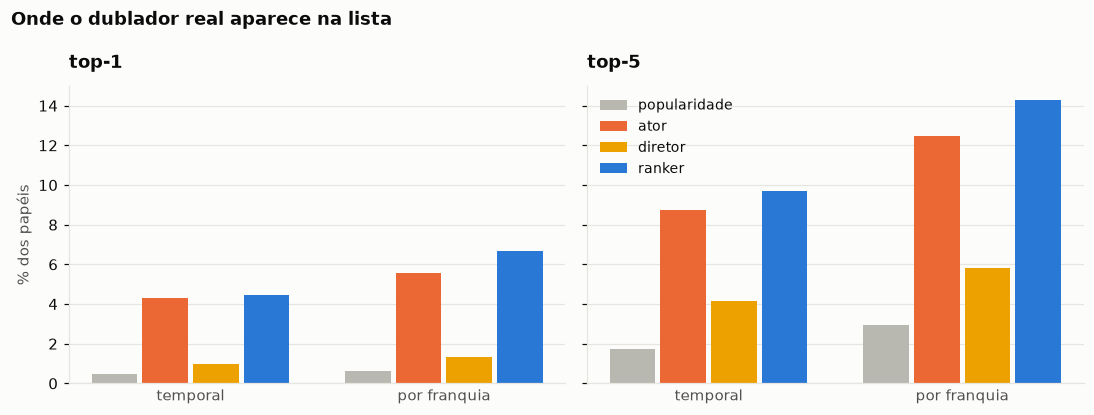

In [3]:
met = m.metricas_validacoes(R)
tabela(["validação", "modelo", "top-1", "top-5", "MRR"],
       [(v, mod, br(x["top-1"]) + "%", br(x["top-5"]) + "%", br(x["MRR"], 3)) for v, mod, x in met])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, metrica in zip(axes, ["top-1", "top-5"]):
    vals = {(v, mod): x[metrica] for v, mod, x in met}
    for i, v in enumerate(["temporal", "franquia"]):
        for j, mod in enumerate(m.MODELOS):
            ax.bar(i + (j - 1.5) * 0.2, vals[(v, mod)], width=0.18, color=CORES[mod], label=mod if i == 0 else None)
    ax.set_xticks([0, 1], ["temporal", "por franquia"]); ax.set_title(metrica); ax.grid(axis="x", visible=False)
    ax.tick_params(axis="x", length=0)
axes[0].set_ylabel("% dos papéis"); axes[1].legend(fontsize=9, loc="upper left")
fig.suptitle("Onde o dublador real aparece na lista", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); fig.savefig(FIGS / "05_modelo_metricas.png", dpi=150, bbox_inches="tight")

**Achado.** Prever o dublador é difícil: no teste temporal (obras de 2018 em diante), o ranker põe o dublador real em primeiro lugar em 4,5% dos papéis e entre os cinco primeiros em 9,7% (MRR 0,079). O baseline mais forte, o dublador mais frequente do ator, faz 4,3% e 8,8%; a popularidade sozinha, 0,5% e 1,7%. Na validação por franquia o ranker chega a 6,7% de top-1 e 14,3% de top-5, contra 5,6% e 12,4% do baseline do ator. O ganho do ranker é consistente, mas pequeno, e o teto é baixo: o dublador real só está na lista curta de candidatos em 38% (temporal) e 50% (franquia) dos papéis.

## Sugestão de elenco: top-10 e top-20

Se o objetivo for sugerir uma lista curta para alguém conferir, a pergunta muda: em que fração dos papéis o dublador real está entre os *k* primeiros? Calculado a partir das posições já salvas, sem retreinar.

| validação | modelo | top-1 | top-5 | top-10 | top-20 |
|---|---:|---:|---:|---:|---:|
| temporal | popularidade | 0,5% | 1,7% | 3,3% | 5,6% |
| temporal | ator | 4,3% | 8,8% | 11,1% | 13,8% |
| temporal | diretor | 1,0% | 4,2% | 7,1% | 12,4% |
| temporal | ranker | 4,5% | 9,7% | 13,8% | 19,8% |
| franquia | popularidade | 0,6% | 2,9% | 5,6% | 9,8% |
| franquia | ator | 5,6% | 12,4% | 16,2% | 20,7% |
| franquia | diretor | 1,4% | 5,8% | 9,8% | 17,2% |
| franquia | ranker | 6,7% | 14,3% | 20,4% | 28,9% |

temporal, top-10: atores vistos 18,8% (ator) x 18,8% (ranker); atores novos 1,8% x 7,6%

temporal, top-20: atores vistos 22,4% (ator) x 25,2% (ranker); atores novos 3,4% x 13,3%

franquia, top-10: atores vistos 20,8% (ator) x 23,9% (ranker); atores novos 3,6% x 10,9%

franquia, top-20: atores vistos 26,0% (ator) x 32,8% (ranker); atores novos 6,2% x 18,6%

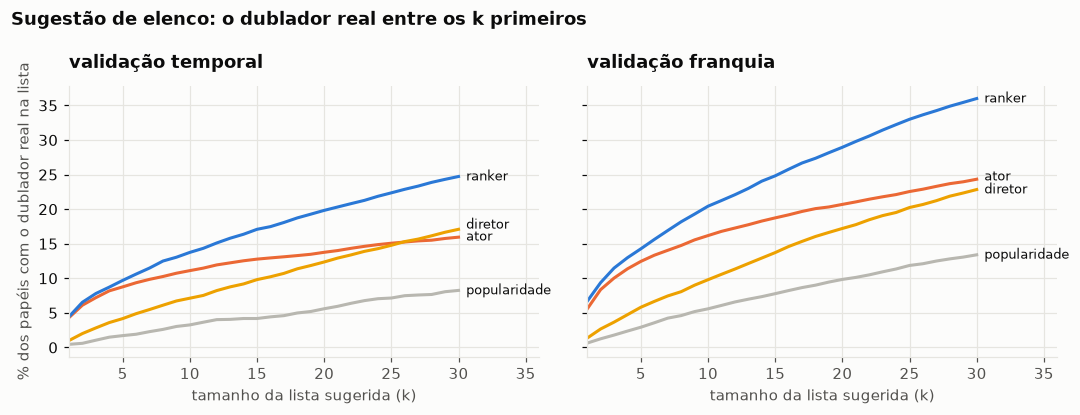

In [4]:
sug = m.sugestao_elenco(R)
tabela(["validação", "modelo", "top-1", "top-5", "top-10", "top-20"],
       [(v, mod, *[br(t[k]) + "%" for k in ("top-1", "top-5", "top-10", "top-20")]) for v, d in sug.items() for mod, t in d.items()])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, v in zip(axes, ["temporal", "franquia"]):
    curva = m.curva_topk(R, v, 30)
    fins = sorted([curva[mod][-1], mod] for mod in m.MODELOS)
    for i in range(1, len(fins)):  # afasta rótulos que colidiriam
        fins[i][0] = max(fins[i][0], fins[i - 1][0] + 1.8)
    for mod in m.MODELOS:
        ax.plot(range(1, 31), curva[mod], color=CORES[mod], linewidth=2, label=mod)
    for y, mod in fins:
        ax.annotate(mod, (30, y), xytext=(5, 0), textcoords="offset points", va="center", fontsize=8.5)
    ax.set_title(f"validação {v}"); ax.set_xlabel("tamanho da lista sugerida (k)"); ax.set_xlim(1, 36)
axes[0].set_ylabel("% dos papéis com o dublador real na lista")
fig.suptitle("Sugestão de elenco: o dublador real entre os k primeiros", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); fig.savefig(FIGS / "08_sugestao_elenco.png", dpi=150, bbox_inches="tight")
for v in ("temporal", "franquia"):
    for k in (10, 20):
        d = m.sugestao_por_recorte(R, k, v)
        display(Markdown(f"{v}, top-{k}: atores vistos {br(d['ator visto no treino']['ator'])}% (ator) x "
                         f"{br(d['ator visto no treino']['ranker'])}% (ranker); atores novos {br(d['ator novo']['ator'])}% x {br(d['ator novo']['ranker'])}%"))

**Achado.** Com uma lista de 20 nomes, o ranker inclui o dublador real em 19,8% dos papéis no teste temporal (contra 13,8% do baseline do ator) e em 28,9% na validação por franquia (contra 20,7%). A vantagem cresce com o tamanho da lista porque o baseline do ator acaba quando o histórico do ator acaba, e o ranker continua com o elenco do estúdio e do diretor. Para atores novos, o top-20 vai de 3,4% para 13,3% (temporal) e de 6,2% para 18,6% (franquia).

## Recortes

Top-5 de cada modelo por mídia, para atores já vistos no treino e atores novos, e para elenco principal e vozes adicionais (pelo nome da seção da página).

In [5]:
rc = m.recortes_validacoes(R, "top-5")
for v in ("temporal", "franquia"):
    display(Markdown(f"**{v}**"))
    tabela(["recorte", "papéis"] + m.MODELOS, [(k, mil(t["n"]), *[br(t[mod]) + "%" for mod in m.MODELOS]) for k, t in rc[v].items()])

**temporal**

| recorte | papéis | popularidade | ator | diretor | ranker |
|---|---:|---:|---:|---:|---:|
| mídia: live-action | 4.480 | 1,6% | 9,8% | 4,6% | 10,7% |
| mídia: animação | 999 | 2,9% | 11,6% | 4,9% | 12,3% |
| mídia: anime | 1.586 | 1,1% | 4,2% | 3,3% | 6,2% |
| mídia: game | 308 | 2,9% | 11,0% | 2,6% | 8,4% |
| ator visto no treino | 4.377 | 2,6% | 15,4% | 4,1% | 14,4% |
| ator novo | 3.623 | 0,7% | 0,7% | 4,3% | 4,0% |
| elenco principal | 6.674 | 1,8% | 9,8% | 4,3% | 10,8% |
| vozes adicionais | 1.326 | 1,4% | 3,5% | 3,3% | 4,2% |

**franquia**

| recorte | papéis | popularidade | ator | diretor | ranker |
|---|---:|---:|---:|---:|---:|
| mídia: live-action | 5.761 | 2,7% | 14,4% | 5,9% | 16,4% |
| mídia: animação | 1.876 | 4,7% | 12,1% | 5,9% | 13,0% |
| mídia: anime | 1.495 | 1,3% | 4,4% | 6,3% | 8,0% |
| mídia: game | 265 | 2,3% | 12,8% | 1,1% | 12,8% |
| ator visto no treino | 7.305 | 3,4% | 16,4% | 6,2% | 17,5% |
| ator novo | 2.695 | 1,6% | 1,6% | 4,8% | 5,5% |
| elenco principal | 8.526 | 3,1% | 13,4% | 6,1% | 15,3% |
| vozes adicionais | 1.474 | 2,1% | 6,9% | 4,5% | 8,4% |

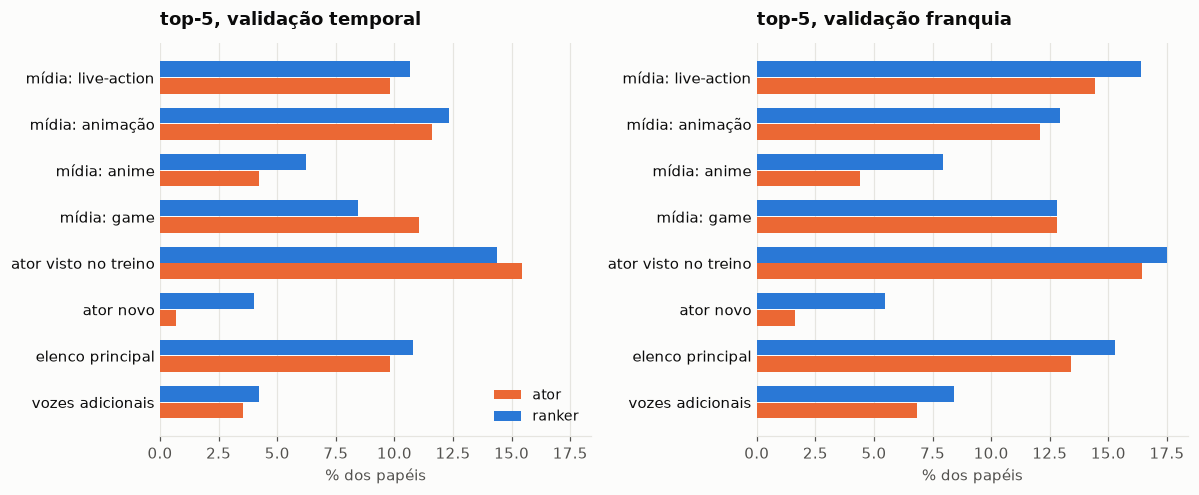

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharex=True)
for ax, v in zip(axes, ["temporal", "franquia"]):
    ks = list(rc[v])[::-1]
    for j, mod in enumerate(["ator", "ranker"]):
        ax.barh([i + (j - 0.5) * 0.36 for i in range(len(ks))], [rc[v][k][mod] for k in ks], height=0.34,
                color=CORES[mod], label=mod)
    ax.set_yticks(range(len(ks)), ks); ax.set_title(f"top-5, validação {v}"); ax.set_xlabel("% dos papéis")
    ax.grid(axis="y", visible=False); ax.tick_params(axis="y", length=0); ax.spines["left"].set_visible(False)
axes[0].legend(fontsize=9, loc="lower right")
fig.tight_layout(); fig.savefig(FIGS / "06_modelo_recortes.png", dpi=150, bbox_inches="tight")

**Achado.** O ranker ganha onde o baseline do ator não tem o que dizer. Para **atores novos** (45% do teste temporal), o top-5 vai de 0,7% para 4,0% (temporal) e de 1,6% para 5,5% (franquia), usando estúdio, diretor e gênero. No **anime**, onde a seiyuu muda de voz a cada personagem, sobe de 4,2% para 6,2%. Para **atores já vistos**, o baseline do ator é tão bom quanto o ranker (15,4% x 14,4% no temporal), e em **games** no temporal o ranker perde (8,4% x 11,0%), com poucos papéis (308). **Vozes adicionais** são quase imprevisíveis (4,2% de top-5 no temporal): são papéis pequenos, distribuídos no elenco da casa.

## O que o ranker usa

Importância por permutação: quanto cai a AUC dos pares papel × candidato quando se embaralha uma feature, numa amostra do teste (temporal) e na média das dobras (franquia).

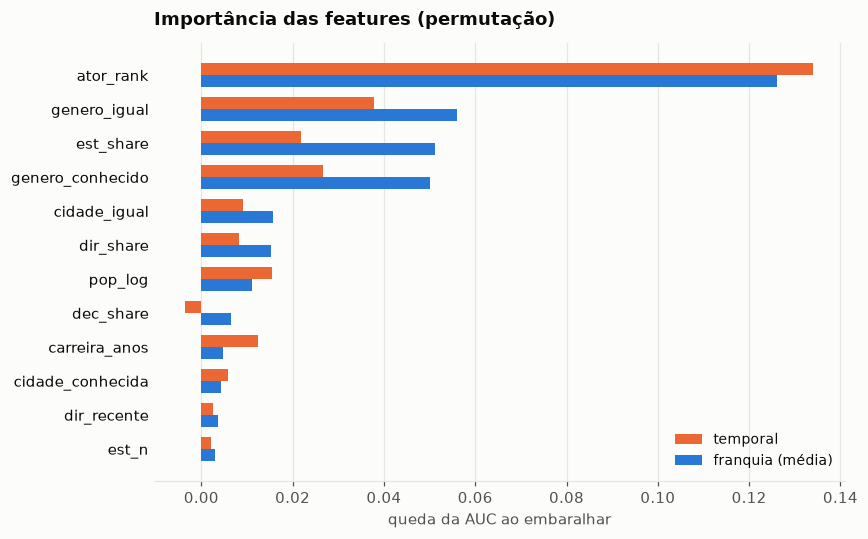

In [7]:
ti, fi = m.importancia_media(R)
top = sorted(fi, key=lambda k: -fi[k])[:12]
fig, ax = plt.subplots(figsize=(8, 5))
y = range(len(top))[::-1]
ax.barh([i + 0.18 for i in y], [ti.get(k, 0) for k in top], height=0.34, color="#eb6834", label="temporal")
ax.barh([i - 0.18 for i in y], [fi[k] for k in top], height=0.34, color="#2a78d6", label="franquia (média)")
ax.set_yticks(list(y), top); ax.set_xlabel("queda da AUC ao embaralhar")
ax.set_title("Importância das features (permutação)"); ax.grid(axis="y", visible=False); ax.tick_params(axis="y", length=0)
ax.spines["left"].set_visible(False); ax.legend(fontsize=9, loc="lower right")
fig.tight_layout(); fig.savefig(FIGS / "07_modelo_importancia.png", dpi=150, bbox_inches="tight")

**Achado.** A posição do candidato na lista de dubladores do ator (`ator_rank`) é de longe a feature mais importante, seguida da compatibilidade de gênero (`genero_igual`, `genero_conhecido`) e da fatia do candidato no estúdio (`est_share`). Diretor, cidade e popularidade ajudam pouco. A atividade recente no estúdio e no diretor, que melhorou a lista de candidatos, quase não muda a ordem dentro dela.

## Exemplos: atores famosos na validação temporal

Papéis de 2018 em diante de atores originais com ficha e 20 ou mais papéis no treino. Primeiro, acertos de primeira; depois, erros em que o dublador real ficou fora do top-5.

In [8]:
for titulo, ex_ in (("Acertos", R["temporal"]["acertos"]), ("Erros", R["temporal"]["erros"])):
    display(Markdown(f"**{titulo}**"))
    tabela(["obra (ano)", "personagem", "ator original", "dublador real", "top-3 do ranker", "posição do real"],
           [(f'{e["obra"]} ({e["ano"]})', e["personagem"], e["ator_original"], e["dublador_real"], ", ".join(e["top3_ranker"]),
             e["rank"] if e["rank"] != float("inf") else "fora das classes") for e in ex_
            if e["dublador_real"] != e["ator_original"]])  # pula "voz original mantida"

**Acertos**

| obra (ano) | personagem | ator original | dublador real | top-3 do ranker | posição do real |
|---|---:|---:|---:|---:|---:|
| Scooby-Doo! & Batman: Os Bravos e Destemidos (2018) | Fred Jones | Frank Welker | Peterson Adriano | Peterson Adriano, Reginaldo Primo, Hércules Franco | 1 |
| Anexo:30ª Temporada de Os Simpsons (2018) | Nelson Muntz | Nancy Cartwright | Paulo Vignolo | Paulo Vignolo, José Leonardo, Christiane Monteiro | 1 |
| 90º Aniversário do Mickey (2018) | Minnie Mouse | Russi Taylor | Mabel Cezar | Mabel Cezar, José Leonardo, Marli Bortoletto | 1 |
| A Missão de Sandy Bochechas (2024) | Clone do Plankton | Doug Lawrence | Guilherme Lopes | Guilherme Lopes, Luiz Laffey, Cassius Romero | 1 |

**Erros**

| obra (ano) | personagem | ator original | dublador real | top-3 do ranker | posição do real |
|---|---:|---:|---:|---:|---:|
| Anexo:31ª Temporada de Os Simpsons (2019) | Filho do Sideshow Mel | Dan Castellaneta | Yago Machado | Jorge Júnior, Mário Tupinambá, Gutemberg Barros | 322 |
| A Maravilhosa Primavera do Mickey Mouse (2022) | Margarida | Tress MacNeille | Izabel Lira | Christiane Louise, Rita Lopes, Aidée Miranda | 22 |
| Bob Esponja: Em Busca da Calça Quadrada (2025) | Narrador Francês | Tom Kenny | Tatá Guarnieri | Wendel Bezerra, Marcelo Pissardini, Luiz Laffey | 18 |
| Diário das Fadas (2023) | Qwak | Dee Bradley Baker | Caio Freire | Dee Bradley Baker, Luiz Laffey, Lucas Almeida | 9 |
| Os Animaniacs (2020) (2020) | Cocoribó | Frank Welker | Milton Parisi | Hércules Franco, Reginaldo Primo, Philippe Maia | 23 |

Os acertos vêm de personagens fixos com voz fixa: Fred Jones com Peterson Adriano, Minnie com Mabel Cezar, Nelson Muntz com Paulo Vignolo. Os erros são de atores de voz que fazem dezenas de personagens por obra (Dan Castellaneta, Tress MacNeille, Tom Kenny, Frank Welker): o ranker aponta o dublador "titular" do ator, mas cada personagem secundário ganha uma voz diferente.

## Conclusão e limitações

- O sinal principal é o histórico do próprio ator. Fora dele, estúdio, diretor e gênero estreitam a busca, mas o elenco de uma casa tem centenas de pessoas: o modelo serve para sugerir uma lista curta (20% de acerto no top-20, temporal), não para acertar o nome.
- **Teto da lista de candidatos**: em 62% dos papéis temporais o dublador real não está na lista curta de candidatos. Aumentar a lista custa tempo e, sem sinal novo, não melhora a ordem.
- **O que falta na base**: gênero e idade do personagem (o ator original é um proxy ruim no anime), o tamanho do papel e a data da dublagem (usamos o ano de lançamento).
- **Dados**: 0,05% dos papéis tinham a voz original numa coluna de dublador; os que têm ficha só de ator original foram retirados, mas atores de voz com ficha de dublador (Dee Bradley Baker, por exemplo) seguem como candidatos quando a voz original foi mantida.
- **Avaliação por amostra**: o ranker treina com 20 mil papéis (12 mil por dobra) e é avaliado em 8 mil papéis do teste temporal e 2 mil por dobra, os mesmos para os quatro modelos; os números têm cerca de ±0,5 ponto de incerteza no top-1.